# Lab 03 - Gaussian Process Modeling
## Tasks
- Construct a Gaussian Process model using GPyTorch and tune hyperparameters of GP model given noisy data
- Construct Gaussian Process models using the Xopt package
- Gaussian Process model visualization and sampling

# Imports

In [1]:
%matplotlib inline

In [2]:
!pip install botorch==0.12.0 gpytorch xopt==2.5.2 -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
%reset -f

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

import torch
import gpytorch

# Gaussian Process modeling

## Generate Data (1D)
We are going to look at some data generated by random sampling in the domain [0,1]. The function that generated this data is

$$
f(x) = \sin(2\pi x) + x
$$

The columns of the array is $(x)$. We need to convert it to a torch tensor to use with GPyTorch.

In [4]:
x = np.random.rand(5)
train_x = x.reshape(-1,1)
train_y = np.sin(2*np.pi*train_x[:,0]) + train_x[:,0] + np.random.randn(train_x.shape[0]) * 0.01

train_x = torch.from_numpy(train_x)
train_y = torch.from_numpy(train_y)

## Define a GP Model in GPyTorch
Here we define an Exact GP model using GPyTorch. The model is exact because we have analytic expressions for the integrals associated with the GP likelihood and output distribution. If we had a non-Gaussian likelihood or some other complication that prevented analytic integration we can also use Variational/Approximate/MCMC techniques to approximate the integrals necessary.

Taking a close look at the model below we see two important modules:
- ```self.mean_module``` which represents the mean function
- ```self.covar_module``` which represents the kernel function (or what is used to calculate the kernel matrix

Both of these objects are torch.nn.Module objects (see https://pytorch.org/docs/stable/generated/torch.nn.Module.html). PyTorch modules have trainable parameters which we can access when doing training. By grouping the modules inside another PyTorch module (gpytorch.models.ExactGP) lets us easily control which parameters are trained and which are not.

In [5]:
class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_f, likelihood):
        super(ExactGPModel, self).__init__(train_x, train_f, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

Here we initialize our model with the training data and a defined likelihood (also a nn.Module) with a trainable noise parameter.

In [6]:
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ExactGPModel(train_x, train_y, likelihood)

NOTE: All PyTorch modules (including ExactGPModel) have ```.train()``` and ```.eval()``` modes. ```train()``` mode is for optimizing model hyperameters. ```.eval()``` mode is for computing predictions through the model posterior.

## Training the model
Here we train the hyperparameters of the model (the parameters of the covar_module and the mean_module) to maximize the marginal log likelihood (minimize the negative marginal log likelihood). Note that since everything is defined in pyTorch we can use Autograd functionality to get the derivatives which will speed up optimization using the modified gradient descent algorithm ADAM.

Also note that several of these hyperparameters (lengthscale and noise) must be strictly positive. Since ADAM is an unconstrained optimizer (which optimizes over the domain (-inf, inf)) gpytorch accounts for this constraint by optimizing the log of the lengthscale (raw_lengthscale). To get the actual lengthscale just use ```model.covar_module.base_kernel.lengthscale.item()```

### **Task:**

Write the steps for minimizing the negative log likelihood using pytorch. Refer back to Lab 1 for a reminder of how to do this. Use `gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)` as the loss function (which we are trying to maximize!). Use your function to train the model and report the marginal log likelihood.


In [7]:
def train_model(model, likelihood):
    # Find optimal model hyperparameters
    model.train()
    likelihood.train()

    #print the new trainable parameters
    for param in model.named_parameters():
        print(f'{param[0]} : {param[1]}')

    optimizer = torch.optim.Adam(model.parameters(),lr=.1)
    loss_metric = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

    for _ in range(100):
        optimizer.zero_grad()
        out = model(train_x)
        loss = -loss_metric(out, train_y)
        loss.backward()
        optimizer.step()

    return loss

In [8]:
nmll = train_model(model, likelihood)

likelihood.noise_covar.raw_noise : Parameter containing:
tensor([0.], requires_grad=True)
mean_module.raw_constant : Parameter containing:
tensor(0., requires_grad=True)
covar_module.raw_outputscale : Parameter containing:
tensor(0., requires_grad=True)
covar_module.base_kernel.raw_lengthscale : Parameter containing:
tensor([[0.]], requires_grad=True)


## Plot the 1D model probability distribution

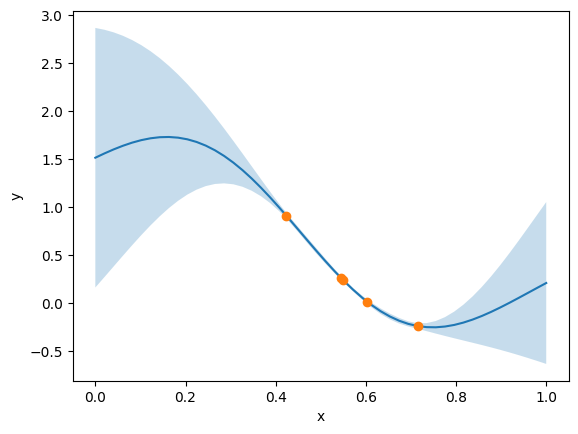

In [9]:
#plot the gp distribution in the normalized range
x = torch.linspace(0, 1, 50).double()
model.eval()
with torch.no_grad():
    p = model(x)

    #get the mean
    m = p.mean

    #get the 2 sigma confidence region around the mean
    l,u = p.confidence_region()

fig,ax = plt.subplots()
ax.set_xlabel('x')
ax.set_ylabel('y')
#plot mean and confidence region
ax.plot(x, m)
ax.fill_between(x.squeeze(), l, u, alpha = 0.25, lw = 0)

#plot samples
ax.plot(train_x, train_y,'oC1')

## Plot the samples from the model

/home/tgrif007/envs/default-pytorch-gpu-2.8.0/lib/python3.10/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


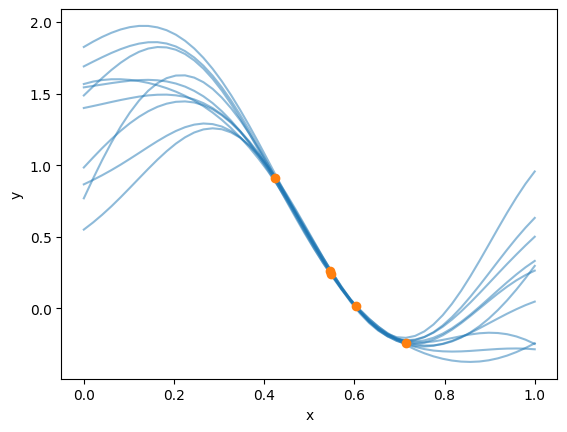

In [10]:
#use the normalized range
x = torch.linspace(0, 1, 50).double()
#specify number of samples
n_samples = 10
model.eval()
with torch.no_grad():
    p = model(x)
    s = p.rsample(torch.Size([n_samples]))

fig,ax = plt.subplots()
ax.set_xlabel('x')
ax.set_ylabel('y')

#plot samples from posterior model
for sample in s:
    ax.plot(x, sample,'C0',alpha = 0.5)

#plot measurements
ax.plot(train_x, train_y,'oC1')

## Building and visualizing models in Xopt
Xopt builds models in Botorch, which has a separate class for GP modeling that loosely wraps ExactGP classes. Visualizing the model has some slight differences.

In [11]:
from xopt.generators.bayesian.models.standard import StandardModelConstructor
from xopt import VOCS
import pandas as pd

vocs = VOCS(variables={"x":[0,1]}, observables=["y"])
data = pd.DataFrame({"x":train_x.flatten().numpy(), "y":train_y.flatten().numpy()})

# define a model constructor
model_constructor = StandardModelConstructor()
xopt_gp_model = model_constructor.build_model_from_vocs(
    vocs=vocs,
    data=data,
)

(<Figure size 600x200 with 1 Axes>,
 array([[<Axes: xlabel='x', ylabel='y'>]], dtype=object))

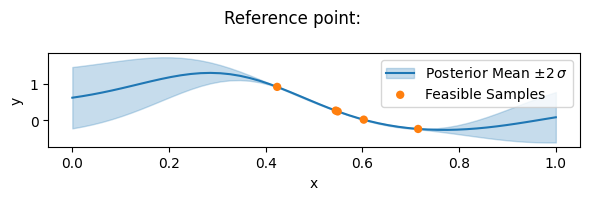

In [12]:
from xopt.generators.bayesian.visualize import visualize_model
visualize_model(xopt_gp_model, vocs, data)

## Generate Data (3D)
We are going to look at some data that was generated by sampling a 5 x 5 x 5 grid in the domain [0,1] on each axis. The function that generated this data is

$$
f(x_1,x_2,x_3) = \sin(2\pi x_1)\sin(\pi x_2) + x_3
$$

The columns of the imported array is $(x_1,x_2,x_3,f)$. We need to convert it to a torch tensor to use with GPyTorch.

In [13]:
x = np.linspace(0,1,5)
xx = np.meshgrid(x,x,x)
train_x = np.vstack([ele.ravel() for ele in xx]).T
train_y = np.sin(2*np.pi*train_x[:,0]) * np.sin(np.pi*train_x[:,1]) + train_x[:,2] + np.random.randn(train_x.shape[0]) * 0.01

train_x = torch.from_numpy(train_x)
train_y = torch.from_numpy(train_y)

### **Task:**
Define a new GP model that uses a different kernel (or combination of kernels) to maximize the marginal log likelihood.


In [14]:
class MyExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super(MyExactGPModel, self).__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()

        self.covar_module = gpytorch.kernels.ScaleKernel(
                                gpytorch.kernels.PeriodicKernel(active_dims = 0) *\
                                gpytorch.kernels.PeriodicKernel(active_dims = 1)
                            ) +\
                            gpytorch.kernels.ScaleKernel(gpytorch.kernels.LinearKernel(active_dims = 2))

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

In [15]:
# train the model
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = MyExactGPModel(train_x, train_y, likelihood)
train_model(model, likelihood)

likelihood.noise_covar.raw_noise : Parameter containing:
tensor([0.], requires_grad=True)
mean_module.raw_constant : Parameter containing:
tensor(0., requires_grad=True)
covar_module.kernels.0.raw_outputscale : Parameter containing:
tensor(0., requires_grad=True)
covar_module.kernels.0.base_kernel.kernels.0.raw_lengthscale : Parameter containing:
tensor([[0.]], requires_grad=True)
covar_module.kernels.0.base_kernel.kernels.0.raw_period_length : Parameter containing:
tensor([[0.]], requires_grad=True)
covar_module.kernels.0.base_kernel.kernels.1.raw_lengthscale : Parameter containing:
tensor([[0.]], requires_grad=True)
covar_module.kernels.0.base_kernel.kernels.1.raw_period_length : Parameter containing:
tensor([[0.]], requires_grad=True)
covar_module.kernels.1.raw_outputscale : Parameter containing:
tensor(0., requires_grad=True)
covar_module.kernels.1.base_kernel.raw_variance : Parameter containing:
tensor([[0.]], requires_grad=True)


/home/tgrif007/envs/default-pytorch-gpu-2.8.0/lib/python3.10/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


tensor(-2.4232, dtype=torch.float64, grad_fn=<NegBackward0>)

### Use the code below to visualize the model.


In [16]:
#Hint: you can use the following code to get the points to be evaluated
import torch
n = 50
x = torch.meshgrid(torch.linspace(0,1,n), torch.linspace(0,1,n))
pts = torch.vstack([ele.flatten() for ele in x]).T
pts = torch.hstack((pts, torch.zeros((n**2,1)))).unsqueeze(1)

pts.shape

/opt/conda/lib/python3.10/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


torch.Size([2500, 1, 3])

In [17]:
# evaluate the model and get the mean + variance
model.eval()

with torch.no_grad():
    post = likelihood(model(pts))
    mean = post.mean
    variance = post.variance

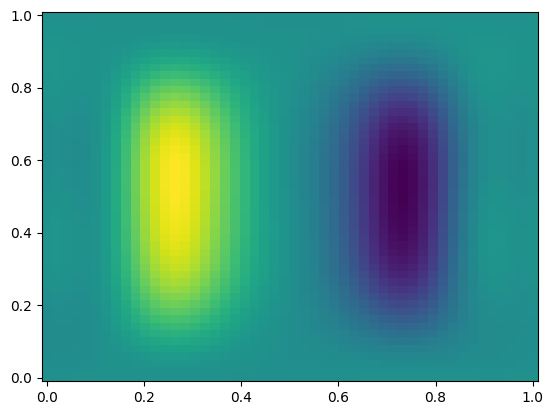

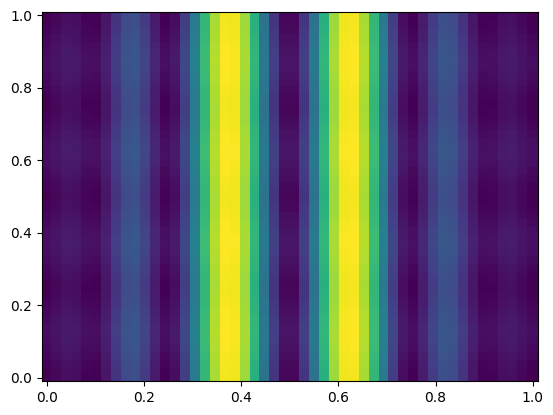

In [18]:
# plot the model
fig, ax = plt.subplots()
ax.pcolor(*x, mean.reshape(n,n))
fig, ax = plt.subplots()
ax.pcolor(*x, variance.reshape(n,n))
